In [1]:
!pip install seaborn

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.layers import Rescaling
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_class_weight

In [3]:
IMG_SIZE = 100
BATCH_SIZE = 32

X_train = tf.keras.utils.image_dataset_from_directory(
    './dataset/chest_xray/train',
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

X_val = tf.keras.utils.image_dataset_from_directory(
    './dataset/chest_xray/train',
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

X_test = tf.keras.utils.image_dataset_from_directory(
    './dataset/chest_xray/test',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

print("Classes:", X_train.class_names)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [4]:
images, labels = next(iter(X_train))

print("Shape of X_train:", images.shape)
print("Shape of X_test:", next(iter(X_test))[0].shape)
print("Shape of Y_train:", labels.shape)
print("Shape of Y_test:", next(iter(X_test))[1].shape)

Shape of X_train: (32, 100, 100, 3)
Shape of X_test: (32, 100, 100, 3)
Shape of Y_train: (32, 1)
Shape of Y_test: (32, 1)


In [5]:
images, labels = next(iter(X_train))

images[1:]

<tf.Tensor: shape=(31, 100, 100, 3), dtype=float32, numpy=
array([[[[2.60000000e+01, 2.60000000e+01, 2.60000000e+01],
         [2.60000000e+01, 2.60000000e+01, 2.60000000e+01],
         [2.60000000e+01, 2.60000000e+01, 2.60000000e+01],
         ...,
         [2.11000000e+02, 2.11000000e+02, 2.11000000e+02],
         [2.13300049e+02, 2.13300049e+02, 2.13300049e+02],
         [2.14000000e+02, 2.14000000e+02, 2.14000000e+02]],

        [[2.50000000e+01, 2.50000000e+01, 2.50000000e+01],
         [2.50000000e+01, 2.50000000e+01, 2.50000000e+01],
         [2.60000000e+01, 2.60000000e+01, 2.60000000e+01],
         ...,
         [2.11000000e+02, 2.11000000e+02, 2.11000000e+02],
         [2.12705948e+02, 2.12705948e+02, 2.12705948e+02],
         [2.14000000e+02, 2.14000000e+02, 2.14000000e+02]],

        [[2.50000000e+01, 2.50000000e+01, 2.50000000e+01],
         [2.50000000e+01, 2.50000000e+01, 2.50000000e+01],
         [2.57000008e+01, 2.57000008e+01, 2.57000008e+01],
         ...,
         [

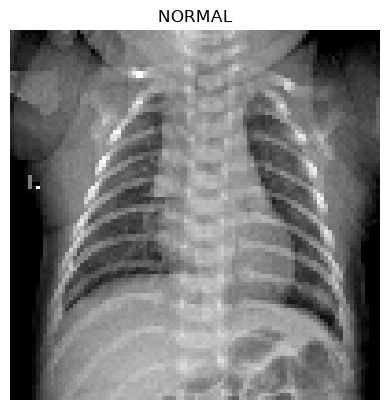

In [6]:
idx = random.randint(0, len(images)-1)

plt.imshow(images[idx].numpy().astype("uint8"))

plt.title(
    "PNEUMONIA" if int(labels[idx][0]) == 1
    else "NORMAL"
)

plt.axis('off')
plt.show()

In [7]:
model = Sequential([

    Rescaling(1./255, input_shape=(100, 100, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(1, activation='sigmoid')
])

c:\Users\lenov\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,166,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,186,305 (8.34 MB)

 Trainable params: 2,186,305 (8.34 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    validation_data=X_val,
    epochs=10
)

Epoch 1/10


c:\Users\lenov\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


131/131 ━━━━━━━━━━━━━━━━━━━━ 20s 144ms/step - accuracy: 0.9022 - loss: 0.2320 - val_accuracy: 0.9655 - val_loss: 0.0954
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 307ms/step - accuracy: 0.9585 - loss: 0.1135 - val_accuracy: 0.9597 - val_loss: 0.1026
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - accuracy: 0.9688 - loss: 0.0793 - val_accuracy: 0.9722 - val_loss: 0.0803
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.9784 - loss: 0.0633 - val_accuracy: 0.9712 - val_loss: 0.0847
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 118ms/step - accuracy: 0.9813 - loss: 0.0472 - val_accuracy: 0.9770 - val_loss: 0.0714
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 18s 136ms/step - accuracy: 0.9806 - loss: 0.0489 - val_accuracy: 0.9722 - val_loss: 0.0872
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 17s 128ms/step - accuracy: 0.9871 - loss: 0.0417 - val_accuracy: 0.9703 - val_loss: 0.0877
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 118ms/step - accuracy: 0.9890 - loss: 0.0271 - val

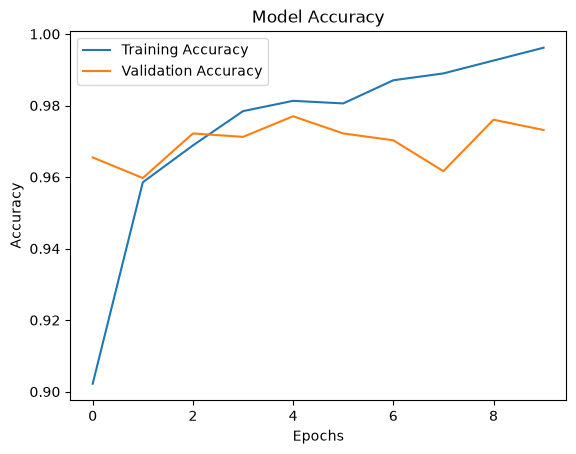

In [10]:
plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

plt.show()

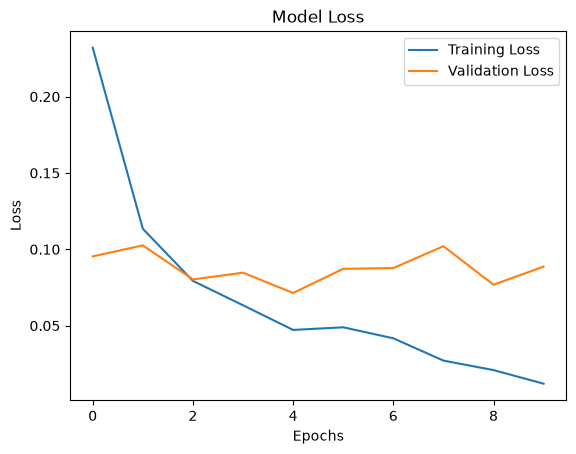

In [11]:
plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(X_test)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 170ms/step - accuracy: 0.7740 - loss: 1.4349
Test Loss: 1.4348798990249634
Test Accuracy: 0.7740384340286255


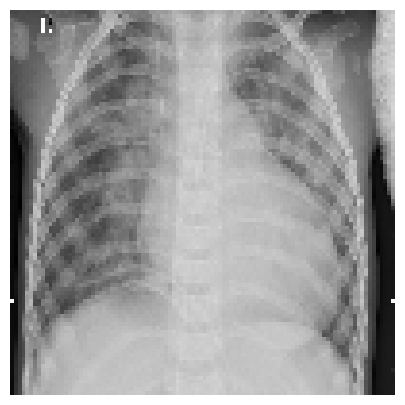

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
Predicted image: PNEUMONIA
Actual image: PNEUMONIA
Prediction probability: 0.9999996


In [16]:
# Get test images and labels
test_images = np.concatenate([
    images.numpy() for images, labels in X_test
])

test_labels = np.concatenate([
    labels.numpy() for images, labels in X_test
])

# Select a random test image
idx2 = random.randint(0, len(test_images)-1)

# Display image
plt.figure(figsize=(5, 5))

plt.imshow(test_images[idx2].astype("uint8"))

plt.axis('off')

plt.show()

# Predict
y_pred = model.predict(
    test_images[idx2].reshape(1, 100, 100, 3)
)

if y_pred[0][0] > 0.5:
    pred = 'PNEUMONIA'
else:
    pred = 'NORMAL'

print("Predicted image:", pred)

print("Actual image:",
      'PNEUMONIA' if test_labels[idx2][0] == 1
      else 'NORMAL')

print("Prediction probability:", y_pred[0][0])